# Quantitative Finance with Machine Learning

## Research Question
Can machine-learning models improve forecasts of financial returns compared with simple baseline models?

## Objectives
- Analyse historical prices and calculate financial returns.
- Engineer features using lagged returns, momentum and volatility.
- Compare a baseline forecast, linear regression and random forest.
- Evaluate forecasts using chronological train/test splits.
- Test a simple trading strategy against buy-and-hold, including transaction costs.

## Tools
Python, pandas, NumPy, Matplotlib and scikit-learn.

In [ ]:
# Install yfinance if not already present
!pip install -q yfinance

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

```markdown
### 1. Data Acquisition and Returns Calculation
We will download 5 years of historical data for SPY (SPDR S&P 500 ETF Trust) and compute daily log returns. Log returns are commonly used in quantitative finance because they are time-additive.
```

In [ ]:
# Download historical data for SPY
ticker = 'SPY'
# Explicitly set group_by='column' or flat columns. Under the hood yfinance uses MultiIndex if a list of tickers is given, but single ticker might have MultiIndex columns now.
data = yf.download(ticker, start='2019-01-01', end='2024-01-01')

# Flatten columns if they are MultiIndex
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.droplevel('Ticker')

# Calculate daily simple returns and daily log returns using the 'Close' price
data['Simple_Return'] = data['Close'].pct_change()
data['Log_Return'] = np.log(data['Close'] / data['Close'].shift(1))

# Drop missing values resulting from lagging
data = data.dropna()

display(data.head())

/tmp/ipykernel_1297/1415094812.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start='2019-01-01', end='2024-01-01')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume,Simple_Return,Log_Return
Date,,,,,,,
2019-01-03,217.924194,221.814901,217.442310,221.511487,144140700,-0.023863,-0.024152
2019-01-04,225.223709,225.866212,220.565569,220.940360,142628800,0.033496,0.032947
2019-01-07,226.999481,228.400485,224.599021,225.491384,103139100,0.007884,0.007854
2019-01-08,229.132278,229.614163,226.660440,229.176913,102512600,0.009396,0.009352
2019-01-09,230.203125,231.041949,228.614718,229.837253,95006600,0.004673,0.004663


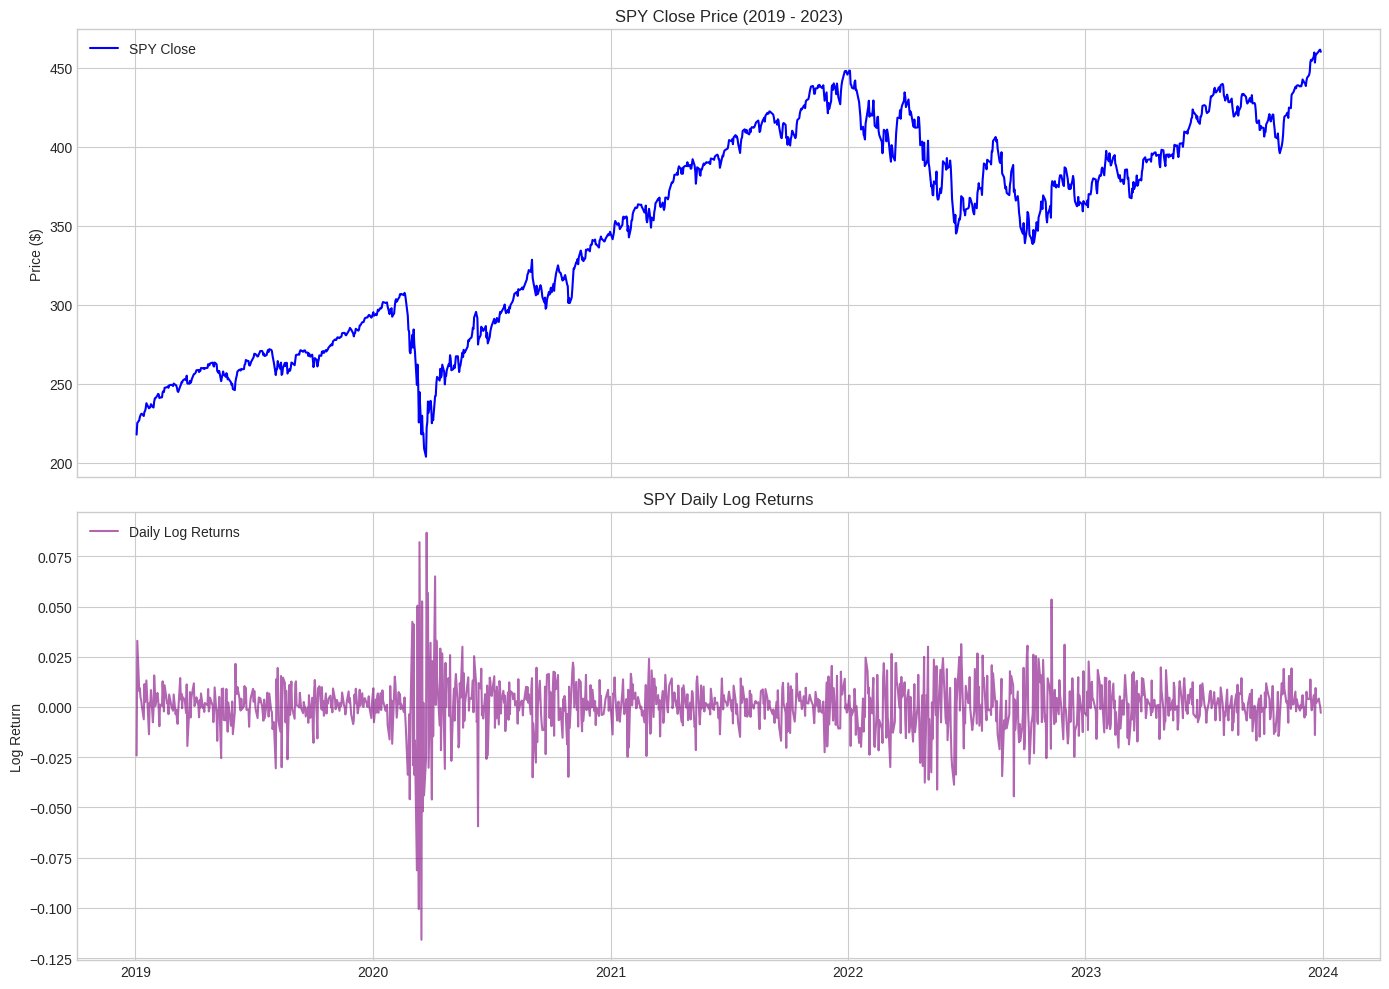

In [ ]:
# Visualize Close Price and Log Returns
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Plot Price
axes[0].plot(data.index, data['Close'], label='SPY Close', color='blue')
axes[0].set_title('SPY Close Price (2019 - 2023)')
axes[0].set_ylabel('Price ($)')
axes[0].legend(loc='upper left')

# Plot Returns
axes[1].plot(data.index, data['Log_Return'], label='Daily Log Returns', color='purple', alpha=0.6)
axes[1].set_title('SPY Daily Log Returns')
axes[1].set_ylabel('Log Return')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
# Summary statistics for daily log returns
print("Daily Log Return Summary")
display(data["Log_Return"].describe())

# Annualised volatility, assuming 252 trading days
daily_volatility = data["Log_Return"].std()
annualised_volatility = daily_volatility * np.sqrt(252)

print(f"Daily volatility: {daily_volatility:.4%}")
print(f"Annualised volatility: {annualised_volatility:.2%}")

Daily Log Return Summary


,Log_Return
count,1257.000000
mean,0.000576
std,0.013281
min,-0.115887
25%,-0.004991
50%,0.000861
75%,0.007210
max,0.086731


Daily volatility: 1.3281%
Annualised volatility: 21.08%


```markdown
### 2. Feature Engineering
We will construct features from our primary dataset. These features will serve as inputs ($X$) for our machine learning models to forecast the next day's log return ($y$).
- **Lags**: 1-day, 2-day, and 5-day lagged log returns.
- **Momentum**: 5-day and 20-day simple moving averages of log returns.
- **Volatility**: 10-day rolling standard deviation of log returns.
```

In [ ]:
# Target: next trading day's log return
data["Target"] = data["Log_Return"].shift(-1)

# Lagged returns: past returns available at today's close
data["Lag_1"] = data["Log_Return"].shift(0)  # Today's return
data["Lag_2"] = data["Log_Return"].shift(1)  # Previous trading day's return
data["Lag_5"] = data["Log_Return"].shift(4)  # Return from 4 trading days ago

# Moving averages of recent returns
data["SMA_5"] = data["Log_Return"].rolling(window=5).mean()
data["SMA_20"] = data["Log_Return"].rolling(window=20).mean()

# Rolling volatility
data["Volatility_10"] = data["Log_Return"].rolling(window=10).std()

# Select model features and target, then remove missing rows
feature_columns = [
    "Lag_1", "Lag_2", "Lag_5",
    "SMA_5", "SMA_20", "Volatility_10"
]

features_df = data[["Target"] + feature_columns].dropna()

display(features_df.head())
print(f"Dataset shape after feature engineering: {features_df.shape}")

Price,Target,Lag_1,Lag_2,Lag_5,SMA_5,SMA_20,Volatility_10
Date,,,,,,,
2019-01-31,0.000482,0.008744,0.015707,0.008426,0.004784,0.003799,0.009202
2019-02-01,0.007011,0.000482,0.008744,-0.007629,0.003195,0.005031,0.009116
2019-02-04,0.004183,0.007011,0.000482,-0.001328,0.006123,0.003734,0.008508
2019-02-05,-0.001319,0.004183,0.007011,0.015707,0.007225,0.003550,0.006494
2019-02-06,-0.009578,-0.001319,0.004183,0.008744,0.003820,0.003017,0.006682


Dataset shape after feature engineering: (1237, 7)


### 3. Model Training and Chronological Splits
We split the dataset sequentially so that the model is evaluated on data that comes strictly after the training period. Then, we fit a baseline, Linear Regression, and Random Forest model.

In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Define features and target
feature_columns = [
    'Lag_1', 'Lag_2', 'Lag_5',
    'SMA_5', 'SMA_20', 'Volatility_10'
]

X = features_df[feature_columns]
y = features_df['Target']

# Chronological split: first 80% train, final 20% test
split_idx = int(len(features_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Training period:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Testing period:", X_test.index.min().date(), "to", X_test.index.max().date())

# 1. Baseline: predict the training-period mean return
y_pred_baseline = np.full(len(y_test), y_train.mean())

# 2. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# 3. Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# Evaluate all models using RMSE
rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print(f"Baseline RMSE: {rmse_baseline:.6f}")
print(f"Linear Regression RMSE: {rmse_lr:.6f}")
print(f"Random Forest RMSE: {rmse_rf:.6f}")


Training period: 2019-01-31 to 2023-01-03
Testing period: 2023-01-04 to 2023-12-28
Baseline RMSE: 0.008244
Linear Regression RMSE: 0.008475
Random Forest RMSE: 0.008236


In [ ]:

from sklearn.metrics import mean_absolute_error

predictions = {
    "Baseline": y_pred_baseline,
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf
}

results = []

for name, pred in predictions.items():
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)

    # Percentage of days where predicted and actual return
    # have the same direction
    directional_accuracy = np.mean(
        np.sign(pred) == np.sign(y_test.to_numpy())
    )

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "Directional Accuracy": directional_accuracy
    })

results_df = pd.DataFrame(results)
display(results_df.round(5))


,Model,RMSE,MAE,Directional Accuracy
0,Baseline,0.00824,0.00644,0.56048
1,Linear Regression,0.00848,0.00672,0.51210
2,Random Forest,0.00824,0.00642,0.56048



### 4. Backtesting a Simple Trading Strategy
Now we will construct a simple rule: if our model predicts a positive return, we take a long position ($+1$); if negative, we take a short/flat position ($0$ or $-1$). Let's simulate this backtest and compare the cumulative returns against a simple buy-and-hold strategy, accounting for a transaction cost of 0.05% per trade.

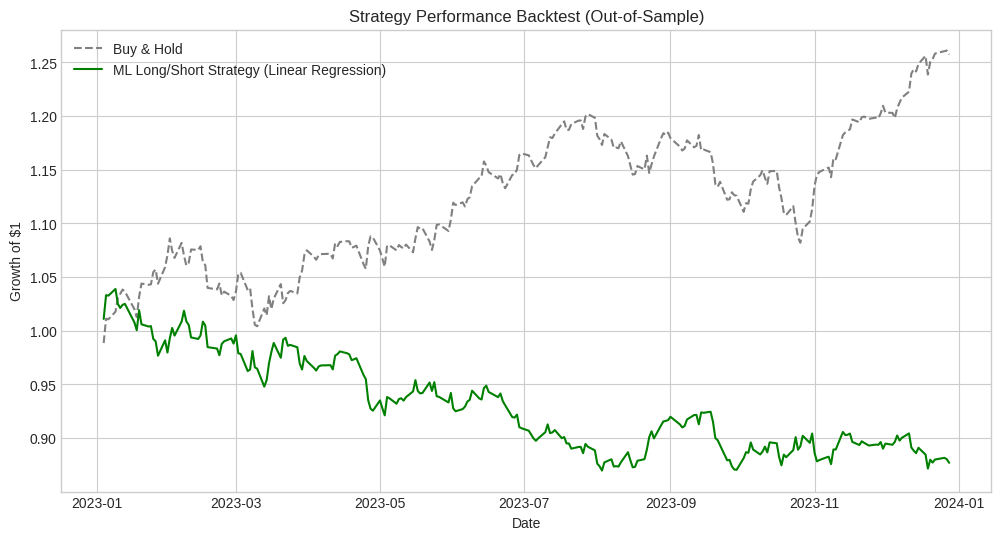

Buy & Hold final value: $1.257 per $1
Strategy final value: $0.877 per $1


In [ ]:

backtest_df = pd.DataFrame(index=y_test.index)
backtest_df["Actual_Return"] = y_test
backtest_df["Predicted_Return"] = y_pred_lr

# Long (+1) if predicted return is positive; short (-1) otherwise
backtest_df["Position"] = np.where(
    backtest_df["Predicted_Return"] > 0, 1, -1
)

# Position changes: 2 units for long-to-short or short-to-long
backtest_df["Trades"] = backtest_df["Position"].diff().abs()

# Include the initial entry as one unit of turnover
backtest_df.iloc[
    0, backtest_df.columns.get_loc("Trades")
] = abs(backtest_df["Position"].iloc[0])

transaction_cost = 0.0005  # 0.05% per unit of position traded

# Strategy return for the next trading day
backtest_df["Gross_Strategy_Return"] = (
    backtest_df["Position"] * backtest_df["Actual_Return"]
)

backtest_df["Net_Strategy_Return"] = (
    backtest_df["Gross_Strategy_Return"]
    - backtest_df["Trades"] * transaction_cost
)

# Cumulative growth, using log returns
backtest_df["Cumulative_Buy_Hold"] = np.exp(
    backtest_df["Actual_Return"].cumsum()
)

backtest_df["Cumulative_Strategy"] = np.exp(
    backtest_df["Net_Strategy_Return"].cumsum()
)

# Plot out-of-sample performance
plt.figure(figsize=(12, 6))
plt.plot(
    backtest_df.index,
    backtest_df["Cumulative_Buy_Hold"],
    label="Buy & Hold",
    color="gray",
    linestyle="--"
)
plt.plot(
    backtest_df.index,
    backtest_df["Cumulative_Strategy"],
    label="ML Long/Short Strategy (Linear Regression)",
    color="green"
)
plt.title("Strategy Performance Backtest (Out-of-Sample)")
plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.legend()
plt.show()

# Summarise final growth
print(
    f"Buy & Hold final value: "
    f"${backtest_df['Cumulative_Buy_Hold'].iloc[-1]:.3f} per $1"
)
print(
    f"Strategy final value: "
    f"${backtest_df['Cumulative_Strategy'].iloc[-1]:.3f} per $1"
)


#### 5. Evaluate Strategy Performance
Calculating total return, annualised return, annualised volatility, Sharpe ratio and maximum draw down for both strategies.

In [ ]:
def calculate_metrics(log_returns, equity_curve):
    log_returns = log_returns.dropna()
    daily_returns = np.expm1(log_returns)

    total_return = equity_curve.iloc[-1] - 1
    years = len(daily_returns) / 252

    annualised_return = (
        equity_curve.iloc[-1] ** (1 / years) - 1
        if years > 0 and equity_curve.iloc[-1] > 0
        else np.nan
    )

    annualised_volatility = daily_returns.std() * np.sqrt(252)

    sharpe_ratio = (
        daily_returns.mean() / daily_returns.std() * np.sqrt(252)
        if daily_returns.std() > 0
        else np.nan
    )

    max_drawdown = (
        equity_curve / equity_curve.cummax() - 1
    ).min()

    return {
        "Total Return": total_return,
        "Annualised Return": annualised_return,
        "Annualised Volatility": annualised_volatility,
        "Sharpe Ratio (rf=0)": sharpe_ratio,
        "Maximum Drawdown": max_drawdown
    }


buy_hold_metrics = calculate_metrics(
    backtest_df["Actual_Return"],
    backtest_df["Cumulative_Buy_Hold"]
)

strategy_metrics = calculate_metrics(
    backtest_df["Net_Strategy_Return"],
    backtest_df["Cumulative_Strategy"]
)

# We transpose the DataFrame (.T) so metrics are columns, which aligns correctly with style formatting subsets
metrics_df = pd.DataFrame({
    "Buy & Hold": buy_hold_metrics,
    "ML Long/Short (LR)": strategy_metrics
}).T

display(metrics_df.style.format("{:.2%}", subset=[
    "Total Return",
    "Annualised Return",
    "Annualised Volatility",
    "Maximum Drawdown"
]).format("{:.3f}", subset=["Sharpe Ratio (rf=0)"]))

,Total Return,Annualised Return,Annualised Volatility,Sharpe Ratio (rf=0),Maximum Drawdown
Buy & Hold,25.74%,26.20%,13.10%,1.843,-9.97%
ML Long/Short (LR),-12.30%,-12.49%,13.24%,-0.941,-16.29%


#### 6. Compare Linear Regression and Random Forest as trading strategies


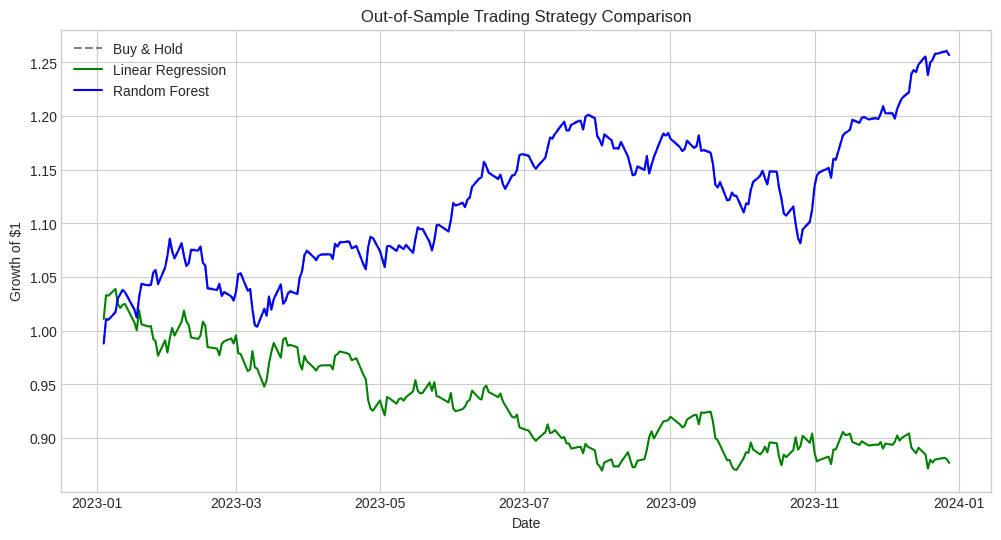

Buy & Hold final value: $1.257
Linear Regression final value: $0.877
Random Forest final value: $1.257


In [ ]:

# Backtest Random Forest using the same test period and costs

rf_backtest = pd.DataFrame(index=y_test.index)
rf_backtest["Actual_Return"] = y_test
rf_backtest["Predicted_Return"] = y_pred_rf

# Long if predicted return is positive; short otherwise
rf_backtest["Position"] = np.where(
    rf_backtest["Predicted_Return"] > 0, 1, -1
)

# Calculate turnover and transaction costs
rf_backtest["Trades"] = rf_backtest["Position"].diff().abs()
rf_backtest.iloc[
    0, rf_backtest.columns.get_loc("Trades")
] = abs(rf_backtest["Position"].iloc[0])

transaction_cost = 0.0005

rf_backtest["Net_Strategy_Return"] = (
    rf_backtest["Position"] * rf_backtest["Actual_Return"]
    - rf_backtest["Trades"] * transaction_cost
)

# Calculate cumulative growth of $1
rf_backtest["Cumulative_Strategy"] = np.exp(
    rf_backtest["Net_Strategy_Return"].cumsum()
)

# Plot the two ML strategies and buy-and-hold
plt.figure(figsize=(12, 6))

plt.plot(
    backtest_df.index,
    backtest_df["Cumulative_Buy_Hold"],
    label="Buy & Hold",
    color="gray",
    linestyle="--"
)

plt.plot(
    backtest_df.index,
    backtest_df["Cumulative_Strategy"],
    label="Linear Regression",
    color="green"
)

plt.plot(
    rf_backtest.index,
    rf_backtest["Cumulative_Strategy"],
    label="Random Forest",
    color="blue"
)

plt.title("Out-of-Sample Trading Strategy Comparison")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.show()

print(f"Buy & Hold final value: ${backtest_df['Cumulative_Buy_Hold'].iloc[-1]:.3f}")
print(f"Linear Regression final value: ${backtest_df['Cumulative_Strategy'].iloc[-1]:.3f}")
print(f"Random Forest final value: ${rf_backtest['Cumulative_Strategy'].iloc[-1]:.3f}")


In [ ]:
# Check why random forest matches buy and hold

print("Random Forest predicted returns:")
display(rf_backtest["Predicted_Return"].describe())

print("\nRandom Forest positions:")
print(rf_backtest["Position"].value_counts())

print(
    "\nPercentage of days Random Forest is long:",
    f"{(rf_backtest['Position'] == 1).mean():.2%}"
)

print(
    "\nPercentage of days Random Forest is short:",
    f"{(rf_backtest['Position'] == -1).mean():.2%}"
)

print(
    "\nNumber of position changes:",
    int(rf_backtest["Trades"].sum())
)


Random Forest predicted returns:


,Predicted_Return
count,248.000000
mean,0.000581
std,0.000130
min,0.000210
25%,0.000535
50%,0.000575
75%,0.000575
max,0.001282



Random Forest positions:
Position
1    248
Name: count, dtype: int64

Percentage of days Random Forest is long: 100.00%

Percentage of days Random Forest is short: 0.00%

Number of position changes: 1


#### 7. Investigate why Random Forest always predicts positive returns

In [ ]:

# Inspect the distribution of Random Forest predictions
print("Random Forest predictions:")
display(rf_backtest["Predicted_Return"].describe())

print(
    "\nMinimum prediction:",
    rf_backtest["Predicted_Return"].min()
)
print(
    "Maximum prediction:",
    rf_backtest["Predicted_Return"].max()
)

# Compare predicted and actual returns
print("\nMean predicted return:", rf_backtest["Predicted_Return"].mean())
print("Mean actual return:", rf_backtest["Actual_Return"].mean())

# Count predictions by direction
print("\nPrediction direction counts:")
print(
    np.where(
        rf_backtest["Predicted_Return"] > 0,
        "Positive",
        "Zero or negative"
    )
)


Random Forest predictions:


,Predicted_Return
count,248.000000
mean,0.000581
std,0.000130
min,0.000210
25%,0.000535
50%,0.000575
75%,0.000575
max,0.001282



Minimum prediction: 0.0002100765621612579
Maximum prediction: 0.0012815733276036198

Mean predicted return: 0.0005813957807564882
Mean actual return: 0.0009235244757606622

Prediction direction counts:
['Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Pos

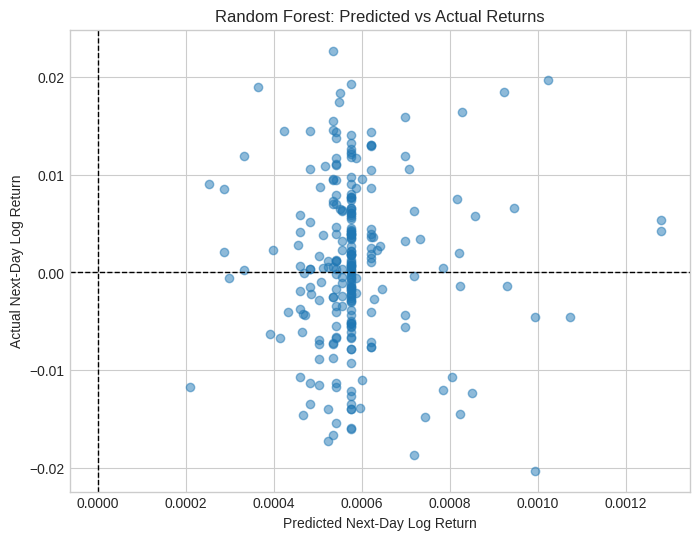

Prediction-return correlation: 0.0099


In [ ]:

# Compare predicted and actual returns
plt.figure(figsize=(8, 6))

plt.scatter(
    rf_backtest["Predicted_Return"],
    rf_backtest["Actual_Return"],
    alpha=0.5
)

plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.axvline(0, color="black", linewidth=1, linestyle="--")

plt.xlabel("Predicted Next-Day Log Return")
plt.ylabel("Actual Next-Day Log Return")
plt.title("Random Forest: Predicted vs Actual Returns")
plt.show()

# Correlation between predictions and actual returns
correlation = rf_backtest[
    ["Predicted_Return", "Actual_Return"]
].corr().iloc[0, 1]

print(f"Prediction-return correlation: {correlation:.4f}")


The correlation between predicted and actual returns is 0.0099. This value is very close to zero, suggesting little linear predictive association in this test period.

In [ ]:
# Compare all models fairly

from sklearn.metrics import mean_absolute_error, mean_squared_error

model_predictions = {
    "Baseline": y_pred_baseline,
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf
}

comparison = []

for name, predictions in model_predictions.items():
    predictions = np.asarray(predictions).ravel()
    actual = y_test.to_numpy().ravel()

    comparison.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "MAE": mean_absolute_error(actual, predictions),
        "Correlation": np.corrcoef(actual, predictions)[0, 1],
        "Directional Accuracy": np.mean(
            np.sign(actual) == np.sign(predictions)
        )
    })

comparison_df = pd.DataFrame(comparison).set_index("Model")
display(comparison_df.round(4))


,RMSE,MAE,Correlation,Directional Accuracy
Model,,,,
Baseline,0.0082,0.0064,0.0000,0.5605
Linear Regression,0.0085,0.0067,-0.0434,0.5121
Random Forest,0.0082,0.0064,0.0099,0.5605


### Model Evaluation Results

The baseline model performed competitively against both machine learning models on the held-out test set. Linear Regression achieved a higher MAE and lower directional accuracy than the baseline, suggesting that the selected lagged returns, moving averages and volatility features did not provide useful predictive information through this model.

Random Forest achieved similar RMSE and MAE to the baseline, but its prediction-return correlation was close to zero. Furthermore, it predicted positive returns throughout the test period, resulting in a strategy that remained long rather than actively identifying changes in market direction.

Overall, the results provide limited evidence that the selected machine learning models improve next-day SPY return forecasts over a simple historical-mean baseline. This highlights the difficulty of predicting daily financial returns and the importance of evaluating models against simple benchmarks. These findings apply to the chosen features, models and test period, rather than proving that machine learning cannot predict financial markets.

In [ ]:

# Step 1: Verify dates, alignment, and predictions

print("Number of test observations:")
print("Actual returns:", len(y_test))
print("Baseline predictions:", len(y_pred_baseline))
print("Linear Regression predictions:", len(y_pred_lr))
print("Random Forest predictions:", len(y_pred_rf))

print("\nTest period:")
print("First date:", y_test.index.min())
print("Last date:", y_test.index.max())

print("\nFirst 5 observations:")
alignment_check = pd.DataFrame({
    "Actual_Next_Day_Return": y_test,
    "Baseline_Prediction": np.asarray(y_pred_baseline),
    "Linear_Regression_Prediction": np.asarray(y_pred_lr),
    "Random_Forest_Prediction": np.asarray(y_pred_rf)
}, index=y_test.index)

display(alignment_check.head())


Number of test observations:
Actual returns: 248
Baseline predictions: 248
Linear Regression predictions: 248
Random Forest predictions: 248

Test period:
First date: 2023-01-04 00:00:00
Last date: 2023-12-28 00:00:00

First 5 observations:


,Actual_Next_Day_Return,Baseline_Prediction,Linear_Regression_Prediction,Random_Forest_Prediction
Date,,,,
2023-01-04,-0.011479,0.000423,-0.002352,0.000502
2023-01-05,0.022673,0.000423,0.004607,0.000535
2023-01-06,-0.000567,0.000423,-0.004439,0.000299
2023-01-09,0.006988,0.000423,0.002793,0.000542
2023-01-10,0.012569,0.000423,-0.000502,0.000575


In [ ]:

# Step 2: Check trading positions and turnover

predictions_dict = {
    "Baseline": np.asarray(y_pred_baseline).ravel(),
    "Linear Regression": np.asarray(y_pred_lr).ravel(),
    "Random Forest": np.asarray(y_pred_rf).ravel()
}

for name, predictions in predictions_dict.items():
    positions = np.where(predictions > 0, 1, -1)
    changes = np.abs(np.diff(positions, prepend=0))

    print(f"\n{name}")
    print("Long days:", np.sum(positions == 1))
    print("Short days:", np.sum(positions == -1))
    print("Position changes (including initial entry):", changes.sum())
    print("First 5 predictions:", np.round(predictions[:5], 6))
    print("First 5 positions:", positions[:5])

print("\nExisting backtest consistency check:")
print("LR positions match:",
      np.array_equal(
          backtest_df["Position"].to_numpy(),
          np.where(np.asarray(y_pred_lr).ravel() > 0, 1, -1)
      ))
print("Transaction cost rate:", transaction_cost)
print("Total LR transaction costs:",
      backtest_df["Trades"].sum() * transaction_cost)



Baseline
Long days: 248
Short days: 0
Position changes (including initial entry): 1
First 5 predictions: [0.000423 0.000423 0.000423 0.000423 0.000423]
First 5 positions: [1 1 1 1 1]

Linear Regression
Long days: 154
Short days: 94
Position changes (including initial entry): 303
First 5 predictions: [-0.002352  0.004607 -0.004439  0.002793 -0.000502]
First 5 positions: [-1  1 -1  1 -1]

Random Forest
Long days: 248
Short days: 0
Position changes (including initial entry): 1
First 5 predictions: [0.000502 0.000535 0.000299 0.000542 0.000575]
First 5 positions: [1 1 1 1 1]

Existing backtest consistency check:
LR positions match: True
Transaction cost rate: 0.0005
Total LR transaction costs: 0.1515


In [ ]:

# Step 3: Rebuild the three strategy backtests consistently

transaction_cost = 0.0005

predictions_dict = {
    "Baseline": np.asarray(y_pred_baseline).ravel(),
    "Linear Regression": np.asarray(y_pred_lr).ravel(),
    "Random Forest": np.asarray(y_pred_rf).ravel()
}

actual_returns = y_test.to_numpy().ravel()
results = {}

for name, predictions in predictions_dict.items():
    bt = pd.DataFrame(index=y_test.index)
    bt["Actual_Return"] = actual_returns
    bt["Predicted_Return"] = predictions

    # Long if predicted return is positive; otherwise short
    bt["Position"] = np.where(bt["Predicted_Return"] > 0, 1, -1)

    # Turnover: 1 unit to enter, 2 units to reverse direction
    bt["Turnover"] = bt["Position"].diff().abs()
    bt.iloc[0, bt.columns.get_loc("Turnover")] = abs(
        bt["Position"].iloc[0]
    )

    bt["Gross_Strategy_Return"] = (
        bt["Position"] * bt["Actual_Return"]
    )
    bt["Net_Strategy_Return"] = (
        bt["Gross_Strategy_Return"]
        - bt["Turnover"] * transaction_cost
    )

    # Compound log returns into equity curves
    bt["Buy_Hold_Equity"] = np.exp(
        bt["Actual_Return"].cumsum()
    )
    bt["Strategy_Equity"] = np.exp(
        bt["Net_Strategy_Return"].cumsum()
    )

    results[name] = bt

summary = pd.DataFrame({
    name: {
        "Final Equity": bt["Strategy_Equity"].iloc[-1],
        "Total Return": bt["Strategy_Equity"].iloc[-1] - 1,
        "Total Turnover": bt["Turnover"].sum(),
        "Total Transaction Costs": (
            bt["Turnover"].sum() * transaction_cost
        ),
        "Days Long": (bt["Position"] == 1).sum(),
        "Days Short": (bt["Position"] == -1).sum()
    }
    for name, bt in results.items()
}).T

buy_hold_equity = np.exp(actual_returns.sum())
print(f"Buy-and-hold final equity: ${buy_hold_equity:.4f} per $1 invested")
display(summary.round(4))


Buy-and-hold final equity: $1.2574 per $1 invested


,Final Equity,Total Return,Total Turnover,Total Transaction Costs,Days Long,Days Short
Baseline,1.2568,0.2568,1.0,0.0005,248.0,0.0
Linear Regression,0.8770,-0.1230,303.0,0.1515,154.0,94.0
Random Forest,1.2568,0.2568,1.0,0.0005,248.0,0.0


In [ ]:
print(data.columns.tolist())
display(data.head())

['Close', 'High', 'Low', 'Open', 'Volume', 'Simple_Return', 'Log_Return', 'Target', 'Lag_1', 'Lag_2', 'Lag_5', 'SMA_5', 'SMA_20', 'Volatility_10']


Price,Close,High,Low,Open,Volume,Simple_Return,Log_Return,Target,Lag_1,Lag_2,Lag_5,SMA_5,SMA_20,Volatility_10
Date,,,,,,,,,,,,,,
2019-01-03,217.924194,221.814901,217.442310,221.511487,144140700,-0.023863,-0.024152,0.032947,-0.024152,NaN,NaN,NaN,NaN,NaN
2019-01-04,225.223709,225.866212,220.565569,220.940360,142628800,0.033496,0.032947,0.007854,0.032947,-0.024152,NaN,NaN,NaN,NaN
2019-01-07,226.999481,228.400485,224.599021,225.491384,103139100,0.007884,0.007854,0.009352,0.007854,0.032947,NaN,NaN,NaN,NaN
2019-01-08,229.132278,229.614163,226.660440,229.176913,102512600,0.009396,0.009352,0.004663,0.009352,0.007854,NaN,NaN,NaN,NaN
2019-01-09,230.203125,231.041949,228.614718,229.837253,95006600,0.004673,0.004663,0.003521,0.004663,0.009352,-0.024152,0.006133,NaN,NaN


In [ ]:

# Step 4A: Calculate next-day open-to-open returns

# Use the original downloaded price data, not features_df.
# Check that the original data has Open and Close columns.
print("Columns:", data.columns.tolist())

# Open-to-open simple return:
# (next day's Open / today's Open) - 1
data["Open_to_Open_Return"] = (
    data["Open"].shift(-1) / data["Open"] - 1
)

display(data[["Open", "Close", "Open_to_Open_Return"]].head())


Columns: ['Close', 'High', 'Low', 'Open', 'Volume', 'Simple_Return', 'Log_Return', 'Target', 'Lag_1', 'Lag_2', 'Lag_5', 'SMA_5', 'SMA_20', 'Volatility_10']


Price,Open,Close,Open_to_Open_Return
Date,,,
2019-01-03,221.511487,217.924194,-0.002578
2019-01-04,220.940360,225.223709,0.020598
2019-01-07,225.491384,226.999481,0.016344
2019-01-08,229.176913,229.132278,0.002881
2019-01-09,229.837253,230.203125,-0.005047


In [ ]:

# Step 5: Align model signals with next-day open-to-open returns

# Keep only dates present in both the model test set and price data
bt_data = pd.DataFrame(index=y_test.index)

# Signal generated using information available at the close of each date
bt_data["Baseline_Prediction"] = np.asarray(y_pred_baseline).ravel()
bt_data["LR_Prediction"] = np.asarray(y_pred_lr).ravel()
bt_data["RF_Prediction"] = np.asarray(y_pred_rf).ravel()

# Forward open-to-open return associated with each signal date
bt_data["Open_to_Open_Return"] = data["Open_to_Open_Return"].reindex(
    bt_data.index
)

# Remove dates without a forward return
bt_data = bt_data.dropna()

print("Observations:", len(bt_data))
print("First date:", bt_data.index.min())
print("Last date:", bt_data.index.max())

display(bt_data.head())


Observations: 248
First date: 2023-01-04 00:00:00
Last date: 2023-12-28 00:00:00


,Baseline_Prediction,LR_Prediction,RF_Prediction,Open_to_Open_Return
Date,,,,
2023-01-04,0.000423,-0.002352,0.000502,-0.003810
2023-01-05,0.000423,0.004607,0.000535,0.002331
2023-01-06,0.000423,-0.004439,0.000299,0.020282
2023-01-09,0.000423,0.002793,0.000542,-0.007993
2023-01-10,0.000423,-0.000502,0.000575,0.012860


In [ ]:

# Step 6: Backtest using open-to-open returns

transaction_cost = 0.0005
strategy_results = {}

prediction_columns = {
    "Baseline": "Baseline_Prediction",
    "Linear Regression": "LR_Prediction",
    "Random Forest": "RF_Prediction"
}

for name, prediction_col in prediction_columns.items():
    bt = bt_data[["Open_to_Open_Return", prediction_col]].copy()
    bt = bt.rename(columns={
        "Open_to_Open_Return": "Actual_Return",
        prediction_col: "Prediction"
    })

    # Long when the signal is positive; short otherwise
    bt["Position"] = np.where(bt["Prediction"] > 0, 1, -1)

    # Turnover includes initial entry and reversals
    bt["Turnover"] = bt["Position"].diff().abs()
    bt.iloc[0, bt.columns.get_loc("Turnover")] = abs(
        bt["Position"].iloc[0]
    )

    bt["Gross_Strategy_Return"] = (
        bt["Position"] * bt["Actual_Return"]
    )

    # Simple-return approximation for trading costs
    bt["Net_Strategy_Return"] = (
        bt["Gross_Strategy_Return"]
        - bt["Turnover"] * transaction_cost
    )

    bt["Equity"] = (1 + bt["Net_Strategy_Return"]).cumprod()
    strategy_results[name] = bt

# Buy-and-hold uses the same open-to-open return series
buy_hold_equity = (1 + bt_data["Open_to_Open_Return"]).cumprod().iloc[-1]

summary = pd.DataFrame({
    name: {
        "Final Equity": bt["Equity"].iloc[-1],
        "Total Return": bt["Equity"].iloc[-1] - 1,
        "Turnover": bt["Turnover"].sum(),
        "Transaction Costs": bt["Turnover"].sum() * transaction_cost,
        "Days Long": (bt["Position"] == 1).sum(),
        "Days Short": (bt["Position"] == -1).sum()
    }
    for name, bt in strategy_results.items()
}).T

print(f"Buy-and-hold final equity: ${buy_hold_equity:.4f} per $1 invested")
display(summary.round(4))


Buy-and-hold final equity: $1.2624 per $1 invested


,Final Equity,Total Return,Turnover,Transaction Costs,Days Long,Days Short
Baseline,1.2618,0.2618,1.0,0.0005,248.0,0.0
Linear Regression,0.4599,-0.5401,303.0,0.1515,154.0,94.0
Random Forest,1.2618,0.2618,1.0,0.0005,248.0,0.0


In [ ]:

# Step 7A: Build features and the open-to-open prediction target

# Forward return: next day's Open to the following day's Open.
# The target is attached to today's date, when the signal is generated.
data["Target_Open_Return"] = (
    data["Open"].shift(-2) / data["Open"].shift(-1) - 1
)

# Features known at today's close
data["Lag_1"] = data["Log_Return"]
data["Lag_2"] = data["Log_Return"].shift(1)
data["Lag_5"] = data["Log_Return"].shift(4)
data["SMA_5"] = data["Log_Return"].rolling(5).mean()
data["SMA_20"] = data["Log_Return"].rolling(20).mean()
data["Volatility_10"] = data["Log_Return"].rolling(10).std()

feature_columns = [
    "Lag_1", "Lag_2", "Lag_5",
    "SMA_5", "SMA_20", "Volatility_10"
]

features_open_df = data[
    ["Target_Open_Return"] + feature_columns
].dropna()

print("Number of observations:", len(features_open_df))
print("First date:", features_open_df.index.min())
print("Last date:", features_open_df.index.max())

display(features_open_df.head())


Number of observations: 1236
First date: 2019-01-31 00:00:00
Last date: 2023-12-27 00:00:00


Price,Target_Open_Return,Lag_1,Lag_2,Lag_5,SMA_5,SMA_20,Volatility_10
Date,,,,,,,
2019-01-31,-0.000148,0.008744,0.015707,0.008426,0.004784,0.003799,0.009202
2019-02-01,0.008626,0.000482,0.008744,-0.007629,0.003195,0.005031,0.009116
2019-02-04,0.001285,0.007011,0.000482,-0.001328,0.006123,0.003734,0.008508
2019-02-05,-0.006782,0.004183,0.007011,0.015707,0.007225,0.003550,0.006494
2019-02-06,-0.008083,-0.001319,0.004183,0.008744,0.003820,0.003017,0.006682


#### 8. Split the data and retrain the models

Using first 80% for training and the final 20% for testing.

In [ ]:

# Step 8: Chronological train/test split and model training

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

X = features_open_df[feature_columns]
y = features_open_df["Target_Open_Return"]

split_idx = int(len(features_open_df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test_open = y.iloc[:split_idx], y.iloc[split_idx:]

# Baseline: predict the average training-set return
y_pred_baseline_open = np.full(len(y_test_open), y_train.mean())

# Linear Regression
lr_model_open = LinearRegression()
lr_model_open.fit(X_train, y_train)
y_pred_lr_open = lr_model_open.predict(X_test)

# Random Forest
rf_model_open = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
rf_model_open.fit(X_train, y_train)
y_pred_rf_open = rf_model_open.predict(X_test)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())


Training observations: 988
Testing observations: 248
Training period: 2019-01-31 00:00:00 to 2022-12-30 00:00:00
Testing period: 2023-01-03 00:00:00 to 2023-12-27 00:00:00


#### 9. Compare forecasting performance
Compare the baseline, Linear Regression, and Random Forest using three metrics:
- RMSE: Penalises larger prediction errors more heavilty. Lower is better.
- MAE: Average absolute prediction error. Lower is better.
- Correlation: Measures how closely predictions move with actual returns. Higher is generally better; a value near zero suggests little linear relationship.

In [ ]:

# Step 9: Evaluate the open-to-open return predictions

predictions_open = {
    "Baseline": y_pred_baseline_open,
    "Linear Regression": y_pred_lr_open,
    "Random Forest": y_pred_rf_open
}

results_open = []

for model_name, predictions in predictions_open.items():
    rmse = np.sqrt(mean_squared_error(y_test_open, predictions))
    mae = mean_absolute_error(y_test_open, predictions)
    correlation = np.corrcoef(y_test_open, predictions)[0, 1]
    directional_accuracy = np.mean(
        np.sign(predictions) == np.sign(y_test_open)
    )

    results_open.append({
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "Correlation": correlation,
        "Directional Accuracy": directional_accuracy
    })

results_open_df = pd.DataFrame(results_open).set_index("Model")

display(results_open_df.round(4))


,RMSE,MAE,Correlation,Directional Accuracy
Model,,,,
Baseline,0.0085,0.0067,0.0000,0.5161
Linear Regression,0.0085,0.0067,0.0522,0.4798
Random Forest,0.0085,0.0067,0.0799,0.5161


In [ ]:

# Step 10: Backtest the open-to-open predictions

backtest_open = pd.DataFrame(index=y_test_open.index)

backtest_open["Actual_Return"] = y_test_open
backtest_open["Baseline_Prediction"] = y_pred_baseline_open
backtest_open["LR_Prediction"] = y_pred_lr_open
backtest_open["RF_Prediction"] = y_pred_rf_open

# Convert predictions into long (+1) or short (-1) positions
for model in ["Baseline", "LR", "RF"]:
    prediction_col = f"{model}_Prediction"
    position_col = f"{model}_Position"

    backtest_open[position_col] = np.where(
        backtest_open[prediction_col] > 0, 1, -1
    )

# Calculate turnover, including the initial entry
for model in ["Baseline", "LR", "RF"]:
    position_col = f"{model}_Position"
    turnover_col = f"{model}_Turnover"

    backtest_open[turnover_col] = (
        backtest_open[position_col].diff().abs()
    )
    backtest_open.iloc[
        0, backtest_open.columns.get_loc(turnover_col)
    ] = abs(backtest_open[position_col].iloc[0])

# Assume transaction costs of 0.05% per unit of turnover
transaction_cost = 0.0005

for model in ["Baseline", "LR", "RF"]:
    position_col = f"{model}_Position"
    turnover_col = f"{model}_Turnover"

    backtest_open[f"{model}_Gross_Return"] = (
        backtest_open[position_col] * backtest_open["Actual_Return"]
    )
    backtest_open[f"{model}_Net_Return"] = (
        backtest_open[f"{model}_Gross_Return"]
        - backtest_open[turnover_col] * transaction_cost
    )

# Buy-and-hold benchmark
backtest_open["Buy_Hold_Return"] = backtest_open["Actual_Return"]

# Compound simple returns to calculate equity curves
for model in ["Baseline", "LR", "RF"]:
    backtest_open[f"{model}_Equity"] = (
        1 + backtest_open[f"{model}_Net_Return"]
    ).cumprod()

backtest_open["Buy_Hold_Equity"] = (
    1 + backtest_open["Buy_Hold_Return"]
).cumprod()

display(backtest_open.head())


,Actual_Return,Baseline_Prediction,LR_Prediction,RF_Prediction,Baseline_Position,LR_Position,RF_Position,Baseline_Turnover,LR_Turnover,RF_Turnover,...,Baseline_Net_Return,LR_Gross_Return,LR_Net_Return,RF_Gross_Return,RF_Net_Return,Buy_Hold_Return,Baseline_Equity,LR_Equity,RF_Equity,Buy_Hold_Equity
Date,,,,,,,,,,,,,,,,,,,,,
2023-01-03,-0.003810,0.000509,0.000536,0.000568,1,1,1,1.0,1.0,1.0,...,-0.004310,-0.003810,-0.004310,-0.003810,-0.004310,-0.003810,0.995690,0.995690,0.995690,0.996190
2023-01-04,0.002331,0.000509,0.001721,0.000457,1,1,1,0.0,0.0,0.0,...,0.002331,0.002331,0.002331,0.002331,0.002331,0.002331,0.998011,0.998011,0.998011,0.998512
2023-01-05,0.020282,0.000509,-0.001731,0.000271,1,-1,1,0.0,2.0,0.0,...,0.020282,-0.020282,-0.021282,0.020282,0.020282,0.020282,1.018253,0.976772,1.018253,1.018764
2023-01-06,-0.007993,0.000509,0.000647,0.000693,1,1,1,0.0,2.0,0.0,...,-0.007993,-0.007993,-0.008993,-0.007993,-0.007993,-0.007993,1.010114,0.967988,1.010114,1.010622
2023-01-09,0.012860,0.000509,0.002106,0.000985,1,1,1,0.0,0.0,0.0,...,0.012860,0.012860,0.012860,0.012860,0.012860,0.012860,1.023104,0.980437,1.023104,1.023618


In [ ]:

# Step 11: Calculate backtest performance metrics

def calculate_metrics(returns, equity, periods_per_year=252):
    returns = returns.dropna()
    equity = equity.loc[returns.index]

    total_return = equity.iloc[-1] - 1

    annualised_return = (
        equity.iloc[-1] ** (periods_per_year / len(returns)) - 1
    )

    annualised_volatility = returns.std(ddof=1) * np.sqrt(periods_per_year)

    if annualised_volatility > 0:
        sharpe_ratio = (
            returns.mean() / returns.std(ddof=1)
        ) * np.sqrt(periods_per_year)
    else:
        sharpe_ratio = np.nan

    running_max = equity.cummax()
    drawdown = equity / running_max - 1
    max_drawdown = drawdown.min()

    return {
        "Total Return": total_return,
        "Annualised Return": annualised_return,
        "Annualised Volatility": annualised_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown": max_drawdown
    }


strategy_columns = {
    "Buy and Hold": ("Buy_Hold_Return", "Buy_Hold_Equity"),
    "Baseline": ("Baseline_Net_Return", "Baseline_Equity"),
    "Linear Regression": ("LR_Net_Return", "LR_Equity"),
    "Random Forest": ("RF_Net_Return", "RF_Equity")
}

metrics = {}

for strategy, (return_col, equity_col) in strategy_columns.items():
    metrics[strategy] = calculate_metrics(
        backtest_open[return_col],
        backtest_open[equity_col]
    )

metrics_df = pd.DataFrame(metrics).T

# Display returns and risk measures as percentages, except Sharpe ratio
percentage_columns = [
    "Total Return",
    "Annualised Return",
    "Annualised Volatility",
    "Maximum Drawdown"
]

display(
    metrics_df.style.format({
        **{col: "{:.2%}" for col in percentage_columns},
        "Sharpe Ratio": "{:.3f}"
    })
)


,Total Return,Annualised Return,Annualised Volatility,Sharpe Ratio,Maximum Drawdown
Buy and Hold,26.24%,26.72%,13.49%,1.823,-9.59%
Baseline,26.18%,26.65%,13.49%,1.819,-9.59%
Linear Regression,7.51%,7.64%,13.53%,0.611,-8.70%
Random Forest,26.18%,26.65%,13.49%,1.819,-9.59%


**The machine-learning models have not demonstrated an advantage over simply holding SPY during the 2023 test period.**

- Buy and Hold: earned 26.24% over the test period.



- Baseline and Random Forest: produced almost identical results to Buy and Hold because they predicted positive returns throughout the test period and therefore stayed long.



- Linear Regression: earned only 7.51%, largely because its long/short signals sometimes positioned against the market.



- Maximum drawdown: Linear Regression had a slightly smaller drawdown, but that came alongside a much lower total return.

In [ ]:

# Step 13: Verify annualised metrics and Sharpe ratios

for strategy, (return_col, equity_col) in strategy_columns.items():
    returns = backtest_open[return_col].dropna()

    annual_return = (
        (1 + returns).prod() ** (252 / len(returns)) - 1
    )
    annual_vol = returns.std(ddof=1) * np.sqrt(252)
    sharpe = (
        returns.mean() / returns.std(ddof=1) * np.sqrt(252)
        if returns.std(ddof=1) > 0 else np.nan
    )

    print(f"{strategy}")
    print(f"  Annualised return: {annual_return:.2%}")
    print(f"  Annualised volatility: {annual_vol:.2%}")
    print(f"  Sharpe ratio: {sharpe:.3f}")
    print()


Buy and Hold
  Annualised return: 26.72%
  Annualised volatility: 13.49%
  Sharpe ratio: 1.823

Baseline
  Annualised return: 26.65%
  Annualised volatility: 13.49%
  Sharpe ratio: 1.819

Linear Regression
  Annualised return: 7.64%
  Annualised volatility: 13.53%
  Sharpe ratio: 0.611

Random Forest
  Annualised return: 26.65%
  Annualised volatility: 13.49%
  Sharpe ratio: 1.819



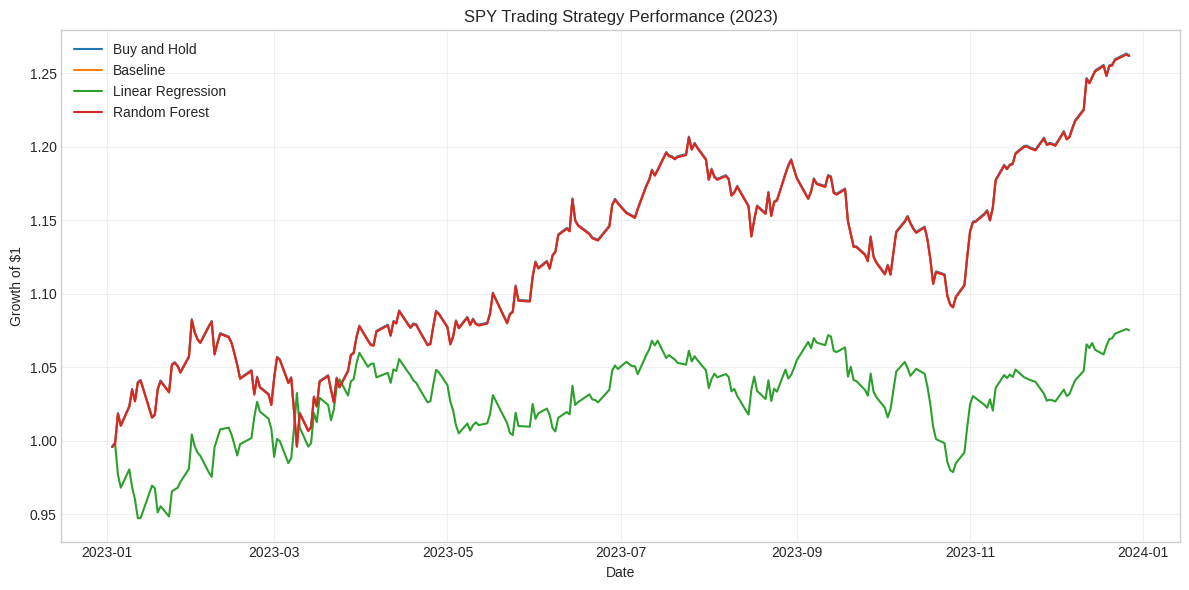

In [ ]:

# Step 15: Plot cumulative equity curves

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    backtest_open.index,
    backtest_open["Buy_Hold_Equity"],
    label="Buy and Hold"
)
plt.plot(
    backtest_open.index,
    backtest_open["Baseline_Equity"],
    label="Baseline"
)
plt.plot(
    backtest_open.index,
    backtest_open["LR_Equity"],
    label="Linear Regression"
)
plt.plot(
    backtest_open.index,
    backtest_open["RF_Equity"],
    label="Random Forest"
)

plt.title("SPY Trading Strategy Performance (2023)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


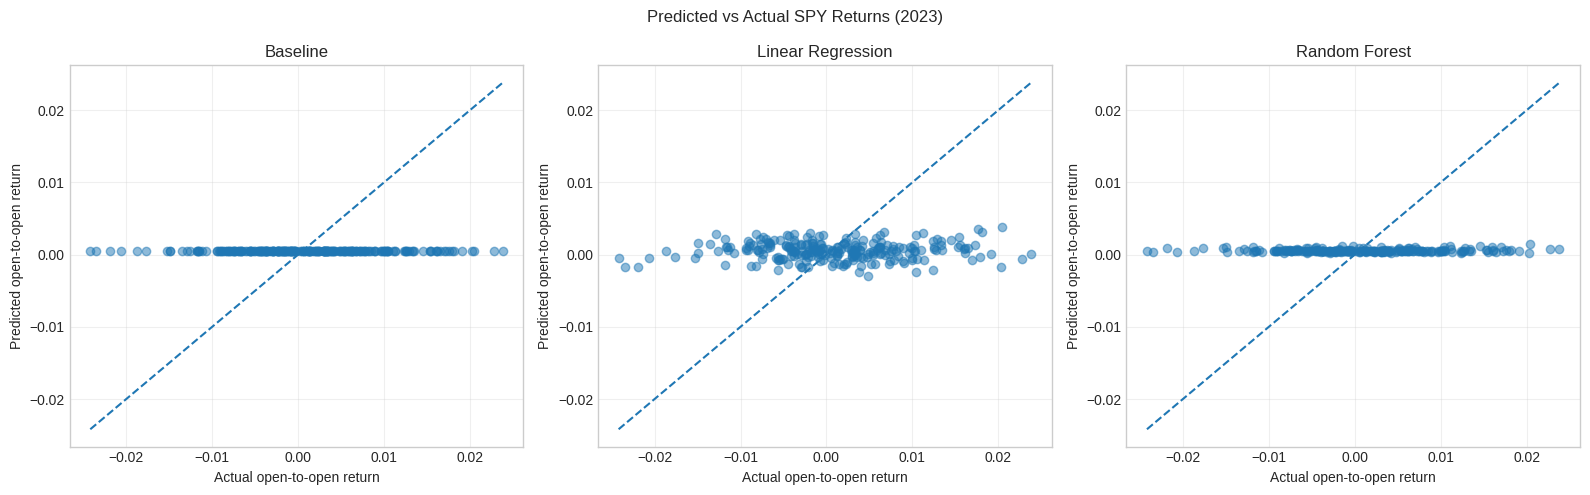

In [ ]:

# Step 16: Compare predicted returns with actual returns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

prediction_plot_data = [
    ("Baseline", y_pred_baseline_open),
    ("Linear Regression", y_pred_lr_open),
    ("Random Forest", y_pred_rf_open)
]

for ax, (model_name, predictions) in zip(axes, prediction_plot_data):
    ax.scatter(y_test_open, predictions, alpha=0.5)

    # Reference line: perfect predictions would lie on this line
    lower = min(y_test_open.min(), predictions.min())
    upper = max(y_test_open.max(), predictions.max())
    ax.plot([lower, upper], [lower, upper], linestyle="--")

    ax.set_title(model_name)
    ax.set_xlabel("Actual open-to-open return")
    ax.set_ylabel("Predicted open-to-open return")
    ax.grid(True, alpha=0.3)

plt.suptitle("Predicted vs Actual SPY Returns (2023)")
plt.tight_layout()
plt.show()


,Feature,Importance
1,Lag_2,0.2901
2,Lag_5,0.1761
0,Lag_1,0.1663
4,SMA_20,0.1393
3,SMA_5,0.1275
5,Volatility_10,0.1006


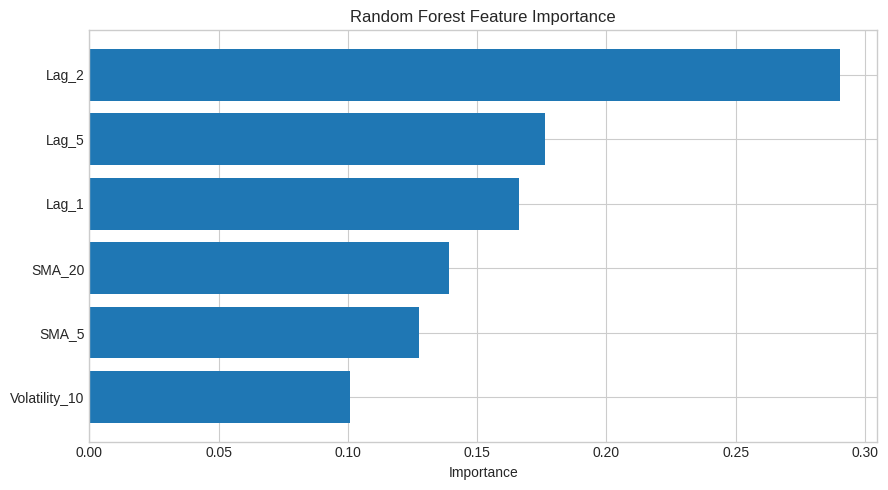

In [ ]:

# Step 17: Examine Random Forest feature importance

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model_open.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


,Feature,Importance_Mean,Importance_Std
2,Lag_5,0.000009,0.000005
1,Lag_2,0.000005,0.000007
0,Lag_1,0.000001,0.000001
3,SMA_5,0.000001,0.000006
4,SMA_20,0.000000,0.000002
5,Volatility_10,0.000000,0.000000


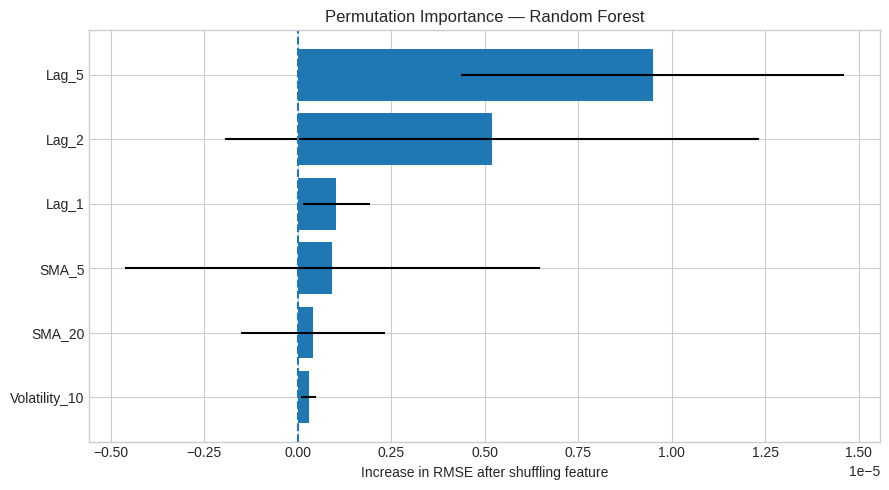

In [ ]:

# Step 18: Permutation importance on the held-out test set

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model_open,
    X_test,
    y_test_open,
    scoring="neg_root_mean_squared_error",
    n_repeats=20,
    random_state=42
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(permutation_df.round(6))

plt.figure(figsize=(9, 5))
plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance_Mean"],
    xerr=permutation_df["Importance_Std"]
)
plt.axvline(0, linestyle="--")
plt.gca().invert_yaxis()
plt.title("Permutation Importance — Random Forest")
plt.xlabel("Increase in RMSE after shuffling feature")
plt.tight_layout()
plt.show()


In [ ]:

# Step 19: Compare models against a zero-return forecast

y_pred_zero = np.zeros(len(y_test_open))

benchmark_predictions = {
    "Zero-return forecast": y_pred_zero,
    "Training-mean baseline": y_pred_baseline_open,
    "Linear Regression": y_pred_lr_open,
    "Random Forest": y_pred_rf_open
}

benchmark_results = []

for name, pred in benchmark_predictions.items():
    benchmark_results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test_open, pred)),
        "MAE": mean_absolute_error(y_test_open, pred),
        "Directional Accuracy": np.mean(
            np.sign(pred) == np.sign(y_test_open)
        )
    })

benchmark_results_df = (
    pd.DataFrame(benchmark_results)
    .set_index("Model")
)

display(benchmark_results_df.round(4))


,RMSE,MAE,Directional Accuracy
Model,,,
Zero-return forecast,0.0085,0.0067,0.0000
Training-mean baseline,0.0085,0.0067,0.5161
Linear Regression,0.0085,0.0067,0.4798
Random Forest,0.0085,0.0067,0.5161


In [ ]:

# Step 20: Show precise forecasting metrics and differences

benchmark_results_df["RMSE"] = [
    np.sqrt(mean_squared_error(
        y_test_open, benchmark_predictions[name]
    ))
    for name in benchmark_results_df.index
]

benchmark_results_df["MAE"] = [
    mean_absolute_error(y_test_open, benchmark_predictions[name])
    for name in benchmark_results_df.index
]

display(benchmark_results_df.style.format({
    "RMSE": "{:.8f}",
    "MAE": "{:.8f}",
    "Directional Accuracy": "{:.2%}"
}))


,RMSE,MAE,Directional Accuracy
Model,,,
Zero-return forecast,0.00853734,0.00667004,0.00%
Training-mean baseline,0.00849424,0.00665670,51.61%
Linear Regression,0.00851614,0.00674343,47.98%
Random Forest,0.00847850,0.00665409,51.61%


# Conclusion

## 1. Research objective

This project investigated whether machine-learning models could predict daily SPY returns using historical market information and whether their predictions could be converted into a profitable trading strategy. The analysis focused on three forecasting approaches: a training-mean baseline, Linear Regression, and Random Forest. The models used six features derived from historical returns: `Lag_1`, `Lag_2`, `Lag_5`, `SMA_5`, `SMA_20`, and `Volatility_10`.

The dataset contained 1,236 observations from 31 January 2019 to 27 December 2023 after feature construction and removal of incomplete rows. The data were divided chronologically into 988 training observations and 248 test observations. The test period ran from 3 January to 27 December 2023. This chronological split ensured that the models were trained on earlier observations and evaluated on a subsequent period, rather than randomly mixing past and future data.

The findings are assessed in two stages: forecasting accuracy and simulated trading performance.

## 2. Forecasting performance

The models were evaluated using root mean squared error (RMSE), mean absolute error (MAE), and directional accuracy. The zero-return forecast and training-mean forecast provided simple benchmarks against which to assess whether machine learning added predictive value.

| Model | RMSE | MAE | Directional accuracy |
|---|---:|---:|---:|
| Zero-return forecast | 0.00853734 | 0.00667004 | 0.00%* |
| Training-mean baseline | 0.00849424 | 0.00665670 | 51.61% |
| Linear Regression | 0.00851614 | 0.00674343 | 47.98% |
| Random Forest | **0.00847850** | **0.00665409** | 51.61% |

*The reported 0.00% directional accuracy for the zero-return forecast results from the scoring convention used for zero predictions. Because a zero prediction has no positive or negative direction, this figure should not be interpreted as the model predicting every market movement incorrectly.*

Random Forest achieved the lowest RMSE and MAE among the four forecasts. However, its improvement over the training-mean baseline was very small. Its RMSE was approximately 0.185% lower in relative terms, while its MAE was approximately 0.039% lower. These percentages describe the relative reductions in error, not percentage-point changes in SPY returns.

Linear Regression performed worse than the training-mean baseline on both measures. Its RMSE was approximately 0.258% higher, and its MAE was approximately 1.303% higher. Its directional accuracy of 47.98% was also below the baseline's 51.61%.

Random Forest and the training-mean baseline both achieved directional accuracy of 51.61%. Therefore, the Random Forest's marginal reduction in numerical prediction error did not translate into improved directional accuracy on the test set.

The absolute forecasting errors remained similar across all models. This indicates that the selected models and features provided limited incremental predictive information about individual daily returns during the evaluation period. Although Random Forest ranked first on RMSE and MAE, the differences are too small on their own to establish a practically meaningful forecasting advantage.

## 3. Feature importance and predictive information

The Random Forest's built-in feature importance scores ranked the features as follows:

| Feature | Built-in importance |
|---|---:|
| `Lag_2` | 0.2901 |
| `Lag_5` | 0.1761 |
| `Lag_1` | 0.1663 |
| `SMA_20` | 0.1393 |
| `SMA_5` | 0.1275 |
| `Volatility_10` | 0.1006 |

`Lag_2` received the highest built-in importance score, suggesting that the fitted forest relied more heavily on this feature when constructing its tree splits. However, built-in feature importance measures how a model uses a feature; it does not establish that the feature contains a stable, economically useful relationship with future returns.

Permutation importance provided a more direct test of how much predictive performance changed when each feature was shuffled. `Lag_5` had the largest mean increase in RMSE, at approximately 0.000009, followed by `Lag_2` at approximately 0.000005. The mean contributions of the remaining features were close to zero.

The permutation importance standard deviations were comparable to or larger than several of the corresponding mean scores. Consequently, the feature ranking is uncertain, and the results do not establish that any individual feature has a reliable predictive effect. Taken together, the two importance analyses suggest that the model learned patterns from the historical features, but there is limited evidence that these patterns substantially improved out-of-sample forecasts.

## 4. Trading strategy performance

Forecasting performance was also evaluated through a simplified trading simulation. Positive predicted returns generated long positions, while negative predicted returns generated short positions. Returns were calculated over the relevant open-to-open holding period, and a transaction cost of 0.05% was deducted for each unit of turnover, including the initial entry.

The resulting performance was compared with a buy-and-hold SPY benchmark.

| Strategy | Total return | Annualised return | Annualised volatility | Sharpe ratio | Maximum drawdown |
|---|---:|---:|---:|---:|---:|
| Buy and Hold | 26.24% | 26.72% | 13.49% | 1.823 | −9.59% |
| Training-mean baseline | 26.18% | 26.65% | 13.49% | 1.819 | −9.59% |
| Linear Regression | 7.51% | 7.64% | 13.53% | 0.611 | −8.70% |
| Random Forest | 26.18% | 26.65% | 13.49% | 1.819 | −9.59% |

Buy-and-hold produced the highest total return, at 26.24%. The training-mean baseline and Random Forest each returned approximately 26.18%, while Linear Regression returned 7.51%.

The close correspondence between the Random Forest, baseline and buy-and-hold results has an important explanation: the baseline and Random Forest predictions were positive throughout the test period. Both strategies therefore maintained long positions rather than successfully switching between long and short exposure in response to changing market conditions. Their results largely reflected exposure to the underlying market.

Accordingly, the Random Forest's backtest should not be interpreted as evidence that it successfully timed the market or generated substantial predictive trading value. Its performance was close to a passive investment strategy, with a small difference consistent with the assumed transaction cost.

Linear Regression's long/short strategy underperformed buy-and-hold by 18.73 percentage points in total return. Its lower maximum drawdown, at −8.70% compared with −9.59%, indicates a somewhat smaller peak-to-trough decline during this particular test period. However, that reduction in drawdown was accompanied by substantially lower returns and a lower Sharpe ratio. It does not establish that Linear Regression offered a superior risk-adjusted investment outcome.

These results illustrate why forecasting error, directional accuracy and trading profitability must be assessed separately. Small differences in prediction error do not necessarily translate into better positions or stronger investment performance. Transaction costs and the frequency and timing of position changes also affect the final outcome.

## 5. Limitations

Several limitations constrain the conclusions that can be drawn from this experiment.

First, the evaluation used a single held-out test period covering 2023. Although the chronological split avoids the main problem of randomly mixing past and future observations, it does not establish whether the results generalise across different market regimes. Performance may differ during periods of high volatility, prolonged declines or changing interest-rate conditions.

Second, the feature set was limited to lagged returns, moving averages and rolling volatility. These variables capture some historical price behaviour but do not include other potentially relevant information, such as trading volume, macroeconomic variables, market breadth or other asset prices. The findings therefore apply to the selected models and feature set, not to every possible machine-learning approach.

Third, the backtest used simplified execution assumptions and a fixed transaction cost. It did not fully model slippage, bid-ask spreads, financing costs associated with short positions, or other real-world implementation constraints. Actual strategy performance could therefore differ from the simulated results.

Fourth, the models were assessed on one test period, and no statistical test or repeated out-of-sample evaluation was conducted to establish whether the small difference between Random Forest and the training-mean baseline was statistically reliable. The observed improvement in RMSE and MAE should consequently be treated as descriptive rather than conclusive evidence of superior predictive ability.

Finally, the trading simulation assumes that signals generated after the close can be acted on at the next opening price. This is a modelling assumption, not a guarantee of execution at that exact price in practice.

## 6. Overall conclusion

The experiment did not demonstrate a meaningful advantage from using Linear Regression or Random Forest to predict daily SPY returns with the selected historical features. Random Forest achieved the lowest test RMSE and MAE, but its error reductions relative to the training-mean baseline were extremely small, and its directional accuracy was unchanged. Linear Regression performed worse than the baseline on both error metrics and produced a substantially weaker trading return.

The trading simulation reinforces this conclusion. Random Forest did not outperform buy-and-hold, because its positive predictions resulted in continuous long exposure throughout the test period. Linear Regression's long/short strategy substantially underperformed the passive benchmark after the assumed transaction costs.

The most defensible conclusion is therefore that **these models, features and evaluation choices did not demonstrate a robust, practically meaningful improvement in daily SPY return forecasting or trading performance over simple benchmarks during the 2023 test period**. This does not prove that machine learning is inherently unsuitable for financial forecasting. Rather, it shows that applying machine learning to noisy daily returns does not automatically produce useful predictive information or a profitable strategy.

A stronger follow-up study would use walk-forward validation across multiple test periods, evaluate whether performance differences are statistically reliable, and test trading assumptions under more realistic transaction costs and execution conditions. Until such evidence is available, the Random Forest's small forecasting improvement should not be interpreted as a dependable investment signal.

Despite the limited predictive results, the project demonstrates a valuable quantitative research process: constructing lagged features, preserving chronological order, comparing models with simple benchmarks, examining feature importance, simulating trades with transaction costs, and distinguishing predictive performance from investment performance. The negative or inconclusive result is itself informative because it prevents a marginal numerical improvement from being mistaken for evidence of a reliable trading advantage.